In [37]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [38]:
# define state

class state(TypedDict):

    weight_kg : float
    height_m : float
    bmi : float
    label : str

In [39]:
# define graph

graph = StateGraph(state)

In [40]:
def calc_bmi(state : state) -> state:
    bmi = state['weight_kg'] / (state['height_m'] * state['height_m'])

    state['bmi'] = round(bmi, 1)

    return state

In [41]:
def label(state : state) -> state:
    if state['bmi'] < 18.5:
        state['label'] = 'UnderWeight'
    elif state['bmi'] >= 18.5 and state['bmi'] <= 24.9:
        state['label'] = 'Normal'
    elif state['bmi'] >= 25 and state['bmi'] <= 29.9:
        state['label'] = 'OverWeight'
    else:
        state['label'] = 'Obese'

    return state
        

In [42]:
#add nodes

graph.add_node('calc', calc_bmi)

graph.add_node('bmi_label', label)

# create edges

graph.add_edge(START, 'calc')

graph.add_edge('calc', 'bmi_label')

graph.add_edge('bmi_label', END)

# compile the graph

workflow = graph.compile()





In [43]:
workflow.invoke({
    'weight_kg' : 62,
    'height_m' : 1.72
})

{'weight_kg': 62, 'height_m': 1.72, 'bmi': 21.0, 'label': 'Normal'}

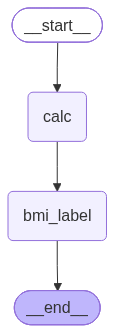

In [44]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())